<a href="https://colab.research.google.com/github/reema-aldaham/Financial-_Tracker/blob/main/Financial__Tracker.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#install yfinance to fetch market data
!pip install yfinance


In [ ]:
#import data manipulation and finance libraries
import yfinance as yf
import pandas as pd


In [ ]:
#download historical daily data for nvidia
data = yf.download("NVDA", start="2023-01-01")

/tmp/ipykernel_659/290369360.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download("NVDA", start="2023-01-01")
[*********************100%***********************]  1 of 1 completed


In [ ]:
#display the first 5 rows of the table
data.head()

Price,Close,High,Low,Open,Volume
Ticker,NVDA,NVDA,NVDA,NVDA,NVDA
Date,,,,,
2023-01-03,14.267298,14.946029,14.049028,14.801512,401277000
2023-01-04,14.699853,14.803506,14.193546,14.518460,431324000
2023-01-05,14.217466,14.515470,14.100856,14.442713,389168000
2023-01-06,14.809484,14.959980,13.987233,14.425766,405044000
2023-01-09,15.575922,16.002495,15.090544,15.233068,504231000


For most daily performance and volatility analysis, investors pay closest attention to the Close (or Adj Close, which accounts for stock splits and dividends).

In Pandas, we can extract just the specific column we want to work with.

In [ ]:
#select only the close column from the dataset
nvda_close = data['Close']
#check the first 5 entries
nvda_close.head()

Ticker,NVDA
Date,
2023-01-03,14.267298
2023-01-04,14.699853
2023-01-05,14.217466
2023-01-06,14.809484
2023-01-09,15.575922


Calculating Daily Returns in Python
Doing this by hand for hundreds of days would take hours, but Pandas has a built-in function called .pct_change() that handles the entire column in one go.

In [ ]:
#calculate daily percentage returns
nvda_returns = nvda_close.pct_change()
#check the first 5 entries
nvda_returns.head()

Ticker,NVDA
Date,
2023-01-03,NaN
2023-01-04,0.030318
2023-01-05,-0.032816
2023-01-06,0.041640
2023-01-09,0.051753


Cleaning Missing Data and Measuring Volatility
Before we can calculate statistics like risk and volatility, we need to remove that empty NaN value so it doesn't interfere with our math. Pandas makes this easy with .dropna().

In [ ]:
#drop missing values
clean_returns = nvda_returns.dropna()
# calcualte voolatility and extrac it as a single numeric value using .items()
daily_volaility = clean_returns.std().item()

#print the formatted result
print(f"Daily Volatility: {daily_volaility * 100:.2f}%")


Daily Volatility: 3.02%


Visualizing Trends with Moving Averages 
Looking at raw tables of numbers makes it hard to see the big picture. Visualizing the price gives us an immediate sense of direction, but daily prices are often noisy.

To smooth out that daily "noise," financial analysts use a Simple Moving Average (SMA).

 Rolling Window: An SMA takes the average closing price over a set period—say, the last 20 days or 50 days—and slides that calculation forward day by day.

Trend Filter: If the current price is consistently above the moving average, the stock is generally in an uptrend; if below, a downtrend

In [ ]:
#1import plotting library
import matplotlib.pyplot as plt

# 2calculate a 20-day simple moving average
data['SMA-20'] = data['Close'].rolling(window=20).mean()


Why it is smoother: The blue line shows every single day's raw price, which jumps around based on daily news or market mood. The orange line averages the last 20 days together. Since one single day only makes up $\frac{1}{20}\text{th}$ of that total calculation, individual daily jumps get smoothed out.
Why it lags behind: When the price suddenly spikes or crashes, the 20-day average takes time to catch up because it is still factoring in the prices from the previous 19 days. In finance, this delay is called lag.

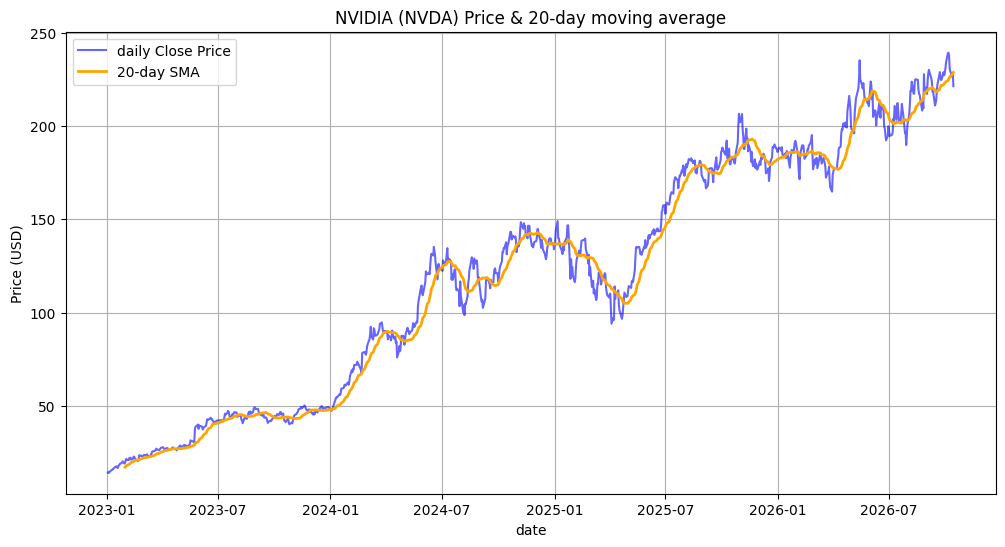

In [ ]:
#3 create the plot
plt.figure(figsize=(12, 6))
plt.plot(data.index, data ['Close'], label= 'daily Close Price', color ='blue', alpha= 0.6)
plt.plot(data.index, data['SMA-20'], label= '20-day SMA', color = 'orange', linewidth= 2)

#4 add titles and labels
plt.title('NVIDIA (NVDA) Price & 20-day moving average')
plt.xlabel('date')
plt.ylabel('Price (USD)')
plt.legend()
plt.grid(True)

#5 display the chart
plt.show()

Calculating NVIDIA's Total Cumulatuse Python to extract the exact starting price from January 2023 and the most recent closing price to see how NVIDIA actually performed

In [ ]:
# extract starting price and end price
initial_price = nvda_close.dropna().iloc[0].item()
final_price = nvda_close.iloc[-1].item()

#calculate cumulative return percentage
cumulative_return = ((final_price - initial_price)/initial_price)*100

#print the results
print(f"initial price (Jan 2023): ${initial_price:.2f}")
print(f"Final price (today): ${final_price:.2f}")
print(f"Cumulative Return: {cumulative_return:.2f}%")

initial price (Jan 2023): $14.27
Final price (today): $221.30
Cumulative Return: 1451.10%


 Calculating NVIDIA's Sharpe Ratio.There are roughly 252 trading days in a stock market year. To convert our daily calculations into an annualized score, we scale the average return by 252 and the volatility by $\sqrt{252}$.

In [ ]:
import numpy as np

# calculate daily avg. return and daiy votatility
mean_daily_return = clean_returns.mean().item()
daily_volatility = clean_returns.std().item()

# compute daily sharpe ratio (risk-free rate =0)
daily_sharpe= mean_daily_return / daily_volatility

#scale up to annualized sharpe ratio
annulaized_sharpe= daily_sharpe* np.sqrt(252)

#print the score
print(f"annualized sharpe ratio: {annulaized_sharpe:.2f}")


annualized sharpe ratio: 1.76
